### Task 4: Textual similarity (15%)
In this task, you will analyze semantic similarity between tweets. You should select 15 examples
of positive sentiment from the dataset and represent each sentence by averaging its word
vectors to obtain a simple sentence-level representation. Based on these representations, you
will compute pairwise cosine similarities between sentences. The similarity computation
should be implemented manually without using pre-built similarity functions.
In your report, you should present the resulting similarity values and discuss which sentence
pairs are most similar and which are least similar, providing an interpretation of these findings.

In [15]:
!pip install nltk
!pip install gensim

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from nltk.tokenize import WhitespaceTokenizer

# load dataset
df = pd.read_csv("../data/TweetSentiment.csv", encoding="latin-1"))
# drop empty row
df = df.dropna(subset=['text'])

# filter
df_positive = df[df['sentiment'] == 'positive']

# sample
df_sample = df_positive.sample(15, random_state=14).copy()
# 14

print("SAMPLE")
print(df_sample)
print("SAMPLE END")

SAMPLE
           textID                                               text  \
4161   d01a499be1   yes! it definitely paid off ... thanks 4 the ...   
10548  da86cad3e8                          wish i was rollin with ya   
15704  0c5515f606   Haha, that`s great. Yeah, Zachary Quinto as S...   
19428  cf07511c16   its cool.  Im glad everyone had a nice date n...   
19033  e8aeca1025               started a great mother`s day season!   
10161  f90f887354  Good Monday morning to everyone- Hope everyone...   
26023  330f415aef          Brian is teaching me soccer!! Lots of fun   
17513  391708c17e   Aww Thanks!    Glad I appreciated the weather...   
22854  68d7756fc4   http://twitpic.com/4jjlc - I love it! If it`s...   
16479  d94f94668e      watching finding nemo with my nephew so cute!   
1980   ff31a70950  Got to go shopping with wife down to Tesco`s. ...   
19794  7fca98d2a2   I know its a Block Party but would love to he...   
2241   7f239881da  Very excited about camp, loads of peop

In [17]:
# Lowercase
df_sample['text'] = df_sample['text'].str.lower()
# Removes all characters that are not letters, numbers, underscores, and whitespaces
df_sample['text'] = df_sample['text'].str.replace(
    r"[^\w\s]",
    '',
    regex=True
)

In [18]:
# tokenize
tokenizer = WhitespaceTokenizer()

df_sample['tokens'] = df_sample['text'].apply(tokenizer.tokenize)

import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
nltk.download('punkt')

stop_words = set(stopwords.words('english'))

# PRE-PROCESS
# remove stop words, digits, underscores
df_sample['tokens_clean'] = df_sample['tokens'].apply(lambda toks: [t for t in toks if t.lower() not in stop_words and t.isalpha()])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [19]:
# load pretrained vectors
import gensim.downloader as api

glove = api.load("glove-twitter-100")

In [20]:

import numpy as np

# generate a sentence vector by averaging the embeddings of all words
def sentence_vector(tokens, prevecs):
    vecs = []
    for tok in tokens:
        if tok in prevecs.key_to_index:
            vecs.append(glove[tok])
        else:
            print(f"NOT INSIDE: {tok}")

    # print(f"LEN VECS: {len(vecs)}")
    # print(f"LEN TOKENS: {len(tokens)}")
    
    # if no words are found in the embedding vocabulary, return a zero vector
    if len(vecs) == 0:
        return np.zeros(prevecs.vector_size)
    return np.mean(vecs, axis=0)  

# generate sentence-level vectors for all selected tweets
sentence_vecs = np.array([sentence_vector(toks, glove) for toks in df_sample['tokens_clean']])

#print(sentence_vecs)

# count the total number of OOV tokens that do not exist in the pre-trained GloVe embeddings
total_oov = sum(1 for toks in df_sample['tokens_clean'] for tok in toks if tok not in glove)
print(f"Total OOV: {total_oov}")


NOT INSIDE: moooooooooooooooo
Total OOV: 1


In [21]:
# cosine similarity
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


n = len(sentence_vecs)
S = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        S[i, j] = cosine_similarity(sentence_vecs[i], sentence_vecs[j])

print(np.round(S, 2))
print("diagonal:", np.round(np.diag(S), 3))

[[1.   0.67 0.86 0.89 0.86 0.87 0.83 0.9  0.81 0.7  0.89 0.86 0.84 0.85
  0.89]
 [0.67 1.   0.67 0.77 0.68 0.71 0.62 0.68 0.74 0.6  0.75 0.74 0.73 0.69
  0.67]
 [0.86 0.67 1.   0.89 0.82 0.85 0.79 0.86 0.82 0.76 0.87 0.86 0.83 0.91
  0.85]
 [0.89 0.77 0.89 1.   0.88 0.93 0.83 0.89 0.91 0.77 0.94 0.94 0.92 0.91
  0.91]
 [0.86 0.68 0.82 0.88 1.   0.92 0.85 0.84 0.83 0.74 0.9  0.84 0.88 0.82
  0.86]
 [0.87 0.71 0.85 0.93 0.92 1.   0.85 0.87 0.87 0.7  0.9  0.86 0.89 0.84
  0.89]
 [0.83 0.62 0.79 0.83 0.85 0.85 1.   0.82 0.78 0.74 0.83 0.77 0.85 0.77
  0.84]
 [0.9  0.68 0.86 0.89 0.84 0.87 0.82 1.   0.84 0.72 0.86 0.82 0.85 0.84
  0.86]
 [0.81 0.74 0.82 0.91 0.83 0.87 0.78 0.84 1.   0.73 0.89 0.91 0.91 0.86
  0.88]
 [0.7  0.6  0.76 0.77 0.74 0.7  0.74 0.72 0.73 1.   0.78 0.71 0.76 0.76
  0.77]
 [0.89 0.75 0.87 0.94 0.9  0.9  0.83 0.86 0.89 0.78 1.   0.91 0.92 0.89
  0.88]
 [0.86 0.74 0.86 0.94 0.84 0.86 0.77 0.82 0.91 0.71 0.91 1.   0.89 0.89
  0.89]
 [0.84 0.73 0.83 0.92 0.88 0.89 0.85 0.8

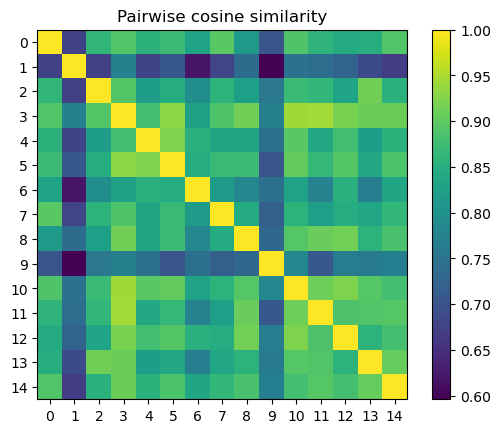

In [22]:
import matplotlib.pyplot as plt
plt.imshow(S, cmap='viridis')
plt.colorbar()
plt.xticks(range(n)); plt.yticks(range(n))
plt.title("Pairwise cosine similarity")

plt.savefig('figure_1')

plt.show()

In [23]:
S_drop_diagonal = S.copy()
np.fill_diagonal(S_drop_diagonal, np.nan)

# find the indices of the most similar sentence pair
i_max, j_max = np.unravel_index(np.nanargmax(S_drop_diagonal), S_drop_diagonal.shape)
# find the indices of the least similar sentence pair
i_min, j_min = np.unravel_index(np.nanargmin(S_drop_diagonal), S_drop_diagonal.shape)

print("most similar:", i_max, j_max, round(S[i_max, j_max], 3))

print(df_sample.iloc[i_max]['text'])
print(df_sample.iloc[j_max]['text'])

print("\nleast similar:", i_min, j_min, round(S[i_min, j_min], 3))

print(df_sample.iloc[i_min]['text'])
print(df_sample.iloc[j_min]['text'])

most similar: 3 11 0.944
 its cool  im glad everyone had a nice date night  maybe one day ill get one too
 i know its a block party but would love to hear a dh original if you get a chance

least similar: 1 9 0.596
 wish i was rollin with ya
watching finding nemo with my nephew so cute


In [24]:
set_a = set(df_sample.iloc[3]['tokens_clean'])
set_b = set(df_sample.iloc[11]['tokens_clean'])
print("3:", set_a)
print("11:", set_b)
print("shared:", set_a & set_b)


3: {'everyone', 'nice', 'date', 'get', 'maybe', 'glad', 'cool', 'im', 'day', 'ill', 'one', 'night'}
11: {'original', 'get', 'love', 'hear', 'dh', 'chance', 'party', 'know', 'would', 'block'}
shared: {'get'}
